# 07 · Data preprocessing

## Purpose

Choose features available in the declared prediction scenario, retain an untouched internal final holdout, and establish reusable train/holdout variables.

## Method

Use the conservative pre-shipment temporal audit, exclude identifiers and unverified history aggregates, and create a stratified 80/20 internal split. Competition test rows are never part of this split.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

Without event-order timestamps, the split is random stratification rather than temporal validation. Feature availability assumptions must be checked against real operational data.

## References

Scikit-learn pipeline guide: https://scikit-learn.org/stable/modules/compose.html


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '07 · Data preprocessing')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 07 · Data preprocessing


,feature,availability_assessment,decision
0,customer_age,likely available by order placement; verify wi...,eligible for pre-shipment candidate set
1,product_price,likely available by order placement; verify wi...,eligible for pre-shipment candidate set
2,discount_percent,likely available by order placement; verify wi...,eligible for pre-shipment candidate set
3,product_rating,likely available by order placement; verify wi...,eligible for pre-shipment candidate set
4,past_purchase_count,historical aggregate; event order and cutoff u...,exclude until leakage-safe construction is ver...
5,past_return_rate,historical aggregate; event order and cutoff u...,exclude until leakage-safe construction is ver...
6,delivery_delay_days,post-shipment outcome,exclude from pre-shipment prediction
7,session_length_minutes,likely available by order placement; verify wi...,eligible for pre-shipment candidate set
8,num_product_views,likely available by order placement; verify wi...,eligible for pre-shipment candidate set
9,device_type,likely available by order placement; verify wi...,eligible for pre-shipment candidate set


Eligible feature columns: ['customer_age', 'product_price', 'discount_percent', 'product_rating', 'session_length_minutes', 'num_product_views', 'device_type', 'product_category', 'shipping_method', 'payment_method', 'used_coupon']
Training rows: 160000 | untouched final holdout rows: 40000
No temporal validation was performed.


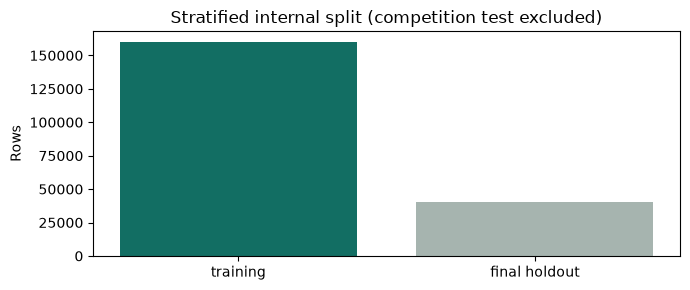

In [2]:
from returnwise.features import select_features, temporal_feature_audit
from returnwise.storage import load_active_dataset
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

frame, manifest = load_active_dataset()
if frame is None or 'returned' not in frame:
    raise RuntimeError('A labeled dataset is required for preprocessing and supervised modeling.')
audit = temporal_feature_audit(list(frame.columns))
display(audit)
feature_columns = select_features(frame, scenario='pre_shipment')
if not feature_columns:
    raise ValueError('The temporal audit left no eligible features.')
X = frame[feature_columns].copy()
y = frame['returned'].astype(int).copy()
train_rows, final_rows = train_test_split(np.arange(len(y)), test_size=0.20, random_state=42, stratify=y)
X_train, X_final = X.iloc[train_rows].reset_index(drop=True), X.iloc[final_rows].reset_index(drop=True)
y_train, y_final = y.iloc[train_rows].reset_index(drop=True), y.iloc[final_rows].reset_index(drop=True)
print('Eligible feature columns:', feature_columns)
print('Training rows:', len(X_train), '| untouched final holdout rows:', len(X_final))
print('No temporal validation was performed.')
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(['training', 'final holdout'], [len(train_rows), len(final_rows)], color=['#126E63', '#A6B4AF'])
ax.set_ylabel('Rows')
ax.set_title('Stratified internal split (competition test excluded)')
plt.tight_layout()
plt.show()
state.update({'feature_columns': feature_columns, 'X_train': X_train, 'y_train': y_train,
              'X_final': X_final, 'y_final': y_final, 'dataset_manifest': manifest})
save_state(state)
